In [1]:
# Verificación del entorno aislado: ejecutar con el kernel tesis-fcl.
import sys
from pathlib import Path
import importlib.metadata as metadata
assert Path(sys.prefix).name == "tesis-fcl", f"Kernel incorrecto: {sys.executable}"
assert sys.version_info[:2] == (3, 12), sys.version
print("Python:", sys.version)
print("Ejecutable:", sys.executable)
for package in ["pandas", "numpy", "scikit-learn", "matplotlib", "openpyxl", "nbclient"]:
    print(package, metadata.version(package))

Python: 3.12.15 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:20:25) [GCC 14.3.0]
Ejecutable: /home/ricardo/miniconda3/envs/tesis-fcl/bin/python
pandas 3.0.6
numpy 2.5.4
scikit-learn 1.9.1
matplotlib 3.11.2
openpyxl 3.1.5
nbclient 0.11.0


In [2]:
import json
import hashlib
import subprocess
import unittest
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from scipy.stats import mannwhitneyu
from matplotlib.ticker import MaxNLocator
ROOT = Path.cwd().resolve()
if not (ROOT / "data/processed/panel_fcl_preliminar.csv").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/feature_engineering.py").exists()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.feature_engineering import build_features, make_preprocessor, REDUNDANT_PREDICTORS
branch = subprocess.check_output(["git", "branch", "--show-current"], cwd=ROOT, text=True).strip()
assert branch in {"feature-engineering", "feature-engineering-semana5-presentacion"}, branch
SOURCE = ROOT / "data/processed/panel_fcl_preliminar.csv"
raw = pd.read_csv(SOURCE, dtype={"RPJ": str, "RUC": str}, encoding="utf-8-sig")
source_sha256 = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
print("Rama:", branch, "| SHA256 fuente:", source_sha256)
print("Dimensiones:", raw.shape)
display(raw.head())
DISPLAY_LABELS = {"D lares": "Dólares", "M todo Directo": "Método Directo", "M todo Indirecto": "Método Indirecto"}
def presentation(frame):
    """Solo presentación: las etiquetas fuente del CSV no cambian."""
    return frame.rename(index=DISPLAY_LABELS).replace(DISPLAY_LABELS)


Rama: feature-engineering | SHA256 fuente: 5e27fa02d209b571c4e4e5da26137d6f12a3d7b8c2c1125f6de2d982a6ac8008
Dimensiones: (4221, 23)


,RPJ,RUC,NombreEmpresa,Ejercicio,TipoEmpresa,TipoSector,CIIU,TipoInformacion,Trimestre,Moneda,...,PatrimonioTotal,TotalIngreso,UtilidadNeta,FCO,CAPEX_reportado,FCL_preliminar,codigo_FCO,codigo_CAPEX,revision_interanual,estado_FCL
0,B30150,20100022142,ABB S.A.,2005,EMPRESAS EMISORAS,INDUSTRIALES,NaN,Anual Individual,Anual,Soles,...,36442,112082,1338,6113.0,-924.0,5189.0,3D01ST,3D0206,False,PRELIMINAR
1,020045,20260172035,ACTIVO INMOBILIARIO PERUANO S.A.A. (ANTES FALA...,2005,EMPRESAS EMISORAS,DIVERSOS,NaN,Anual Individual,Anual,Soles,...,465014,11649,105017,69166.0,0.0,69166.0,3D01ST,3D0206,False,PRELIMINAR
2,B80018,20100047307,ADMINISTRADORA DEL COMERCIO S.A. EN LIQUIDACION,2005,EMPRESAS EMISORAS,DIVERSOS,NaN,Anual Individual,Anual,Soles,...,35123,1896,-19400,2281.0,-127.0,2154.0,3D01ST,3D0206,True,PRELIMINAR
3,023106,20332600592,AENZA S.A.A.,2005,EMPRESAS EMISORAS,DIVERSOS,NaN,Anual Individual,Anual,Soles,...,238945,9137,32724,22565.0,0.0,22565.0,3D01ST,3D0206,False,PRELIMINAR
4,AFP005,20143980821,AFP HORIZONTE S.A.,2005,EMPRESAS EMISORAS,A.F.P.,NaN,Anual Individual,Anual,Soles,...,131862,163205,76517,63690.0,-1210.0,62480.0,3D01ST,3D0206,False,PRELIMINAR


,tipo,faltantes,faltantes_pct
RPJ,str,0,0.00
RUC,str,0,0.00
NombreEmpresa,str,0,0.00
Ejercicio,int64,0,0.00
TipoEmpresa,str,0,0.00
TipoSector,str,0,0.00
CIIU,float64,3872,91.73
TipoInformacion,str,0,0.00
Trimestre,str,0,0.00
Moneda,str,0,0.00


,registros,empresas,fcl_disponible
Ejercicio,,,
2005,194,194,158
2006,189,189,167
2007,202,202,177
2008,207,207,180
2009,212,212,180
2010,213,213,155
2011,216,216,151
2012,221,221,182
2013,217,217,215


,registros
Moneda,
Soles,3697
Dólares,524


Estados del FCL: {'PRELIMINAR': 3898, 'INCOMPLETO': 301, 'REVISAR_CAPEX_POSITIVO': 22}
CAPEX positivo: 22
Bandera revision_interanual: {False: 2950, True: 1271}
Longitud por empresa: {'count': 336.0, 'mean': 12.5625, 'std': 7.269787715802699, 'min': 1.0, '25%': 6.0, '50%': 13.0, '75%': 21.0, 'max': 21.0}
Empresas con cambios de moneda: 35
Saltos entre años: 15


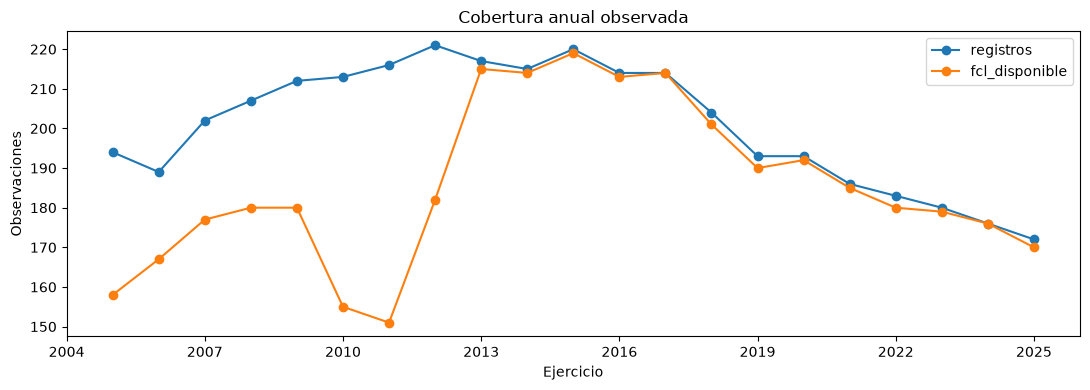

In [3]:
assert not raw.duplicated(["RPJ", "Ejercicio"]).any()
quality = pd.DataFrame({"tipo": raw.dtypes.astype(str), "faltantes": raw.isna().sum(),
                        "faltantes_pct": raw.isna().mean().mul(100).round(2)})
display(quality)
coverage = raw.groupby("Ejercicio").agg(registros=("RPJ", "size"), empresas=("RPJ", "nunique"),
                                        fcl_disponible=("FCL_preliminar", "count"))
display(coverage)
display(presentation(raw.Moneda.value_counts().rename("registros").to_frame()))
valid = raw.FCL_preliminar.notna()
assert np.allclose(raw.loc[valid, "FCL_preliminar"],
                   raw.loc[valid, "FCO"] + raw.loc[valid, "CAPEX_reportado"])
print("Estados del FCL:", raw.estado_FCL.value_counts().to_dict())
print("CAPEX positivo:", int(raw.CAPEX_reportado.gt(0).sum()))
print("Bandera revision_interanual:", raw.revision_interanual.value_counts().to_dict())
histories = raw.groupby("RPJ").Ejercicio.agg(["min", "max", "count"])
print("Longitud por empresa:", histories["count"].describe().to_dict())
print("Empresas con cambios de moneda:", int(raw.groupby("RPJ").Moneda.nunique().gt(1).sum()))
ordered = raw.sort_values(["RPJ", "Ejercicio"])
print("Saltos entre años:", int(ordered.groupby("RPJ").Ejercicio.diff().gt(1).sum()))
coverage[["registros", "fcl_disponible"]].plot(figsize=(11, 4), marker="o", title="Cobertura anual observada")
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.ylabel("Observaciones"); plt.tight_layout(); plt.show()

In [4]:
features, PREDICTORS, dictionary = build_features(raw)
assert len(features) == len(raw)
assert "objetivo_fcl_t1" not in PREDICTORS
print("Predictores construidos:", len(PREDICTORS))
display(dictionary[dictionary.rol.eq("predictor")][["nombre", "formula", "unidad"]])
display(features[["RPJ", "Ejercicio"] + PREDICTORS[:12]].head())

Predictores construidos: 22


,nombre,formula,unidad
0,pasivo_activo,"1 × PasivoTotal(t) / ActivoTotal(t), denominad...",adimensional
1,margen_neto,"1 × UtilidadNeta(t) / TotalIngreso(t), denomin...",adimensional
2,rentabilidad_activo_cierre,"1 × UtilidadNeta(t) / ActivoTotal(t), denomina...",adimensional
3,rotacion_activo_cierre,"1 × TotalIngreso(t) / ActivoTotal(t), denomina...",adimensional
4,fco_activo,"1 × FCO(t) / ActivoTotal(t), denominador > 0",adimensional
5,fco_ingresos,"1 × FCO(t) / TotalIngreso(t), denominador > 0",adimensional
6,inversion_capex_activo,"-1 × CAPEX_reportado(t) / ActivoTotal(t), deno...",adimensional
7,fcl_activo,"1 × FCL_preliminar(t) / ActivoTotal(t), denomi...",adimensional
8,crecimiento_ActivoTotal,(ActivoTotal(t) - ActivoTotal(t-1)) / ActivoTo...,adimensional
9,crecimiento_TotalIngreso,(TotalIngreso(t) - TotalIngreso(t-1)) / TotalI...,adimensional


,RPJ,Ejercicio,pasivo_activo,margen_neto,rentabilidad_activo_cierre,rotacion_activo_cierre,fco_activo,fco_ingresos,inversion_capex_activo,fcl_activo,crecimiento_ActivoTotal,crecimiento_TotalIngreso,cambio_FCO_activo_previo,FCO_lag1
0,000355,2015,0.605997,0.050428,0.073616,1.459814,-0.002230,-0.001528,0.011075,-0.013305,NaN,NaN,NaN,NaN
1,000355,2016,0.612633,0.010403,0.011009,1.058224,0.090598,0.085613,0.035945,0.054653,0.043390,-0.243643,0.096759,-1792.0
2,000355,2017,0.702129,0.019132,0.021333,1.115007,0.110364,0.098981,0.025395,0.084969,0.346609,0.418866,0.058020,75965.0
3,000355,2018,0.682628,0.014680,0.018402,1.253561,-0.062830,-0.050121,0.008777,-0.071607,-0.033791,0.086273,-0.171071,124614.0
4,000355,2019,0.807477,-0.114042,-0.155075,1.359805,-0.046395,-0.034119,0.009850,-0.056245,-0.093240,-0.016389,0.020761,-68545.0


,registros_disponibles
FCO_lag1,3734
FCO_lag2,3392
FCO_lag3,3073
FCO_mean3_previa,3013
FCO_std3_previa,3013
FCL_preliminar_lag1,3506
FCL_preliminar_lag2,3169
FCL_preliminar_lag3,2854
FCL_preliminar_mean3_previa,2766
FCL_preliminar_std3_previa,2766


,FCO_lag1,FCO_lag2,FCO_lag3,FCO_mean3_previa,FCO_std3_previa,FCL_preliminar_lag1,FCL_preliminar_lag2,FCL_preliminar_lag3,FCL_preliminar_mean3_previa,FCL_preliminar_std3_previa
Moneda,,,,,,,,,,
Dólares,444,387,337,321,321,444,387,337,321,321
Soles,3290,3005,2736,2692,2692,3062,2782,2517,2445,2445


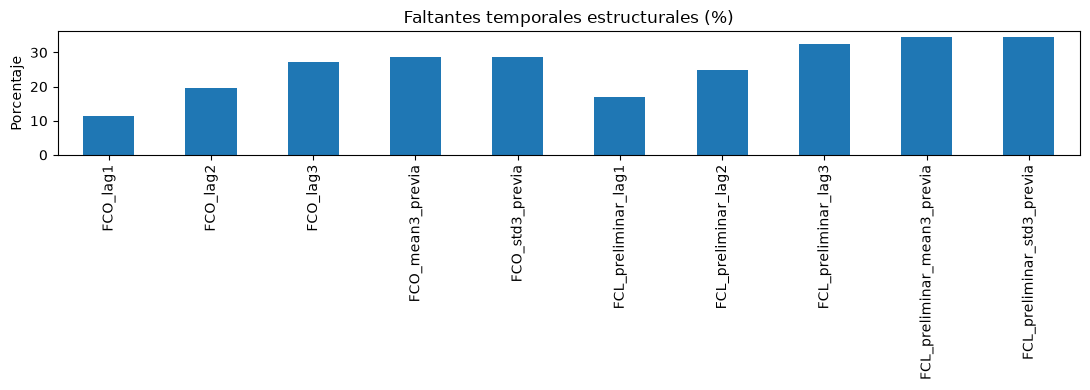

In [5]:
temporal = [c for c in PREDICTORS if "lag" in c or "previa" in c]
display(features[temporal].notna().sum().rename("registros_disponibles").to_frame())
display(presentation(features.groupby("Moneda")[temporal].count()))
features[temporal].isna().mean().mul(100).plot.bar(figsize=(11, 4), title="Faltantes temporales estructurales (%)")
plt.ylabel("Porcentaje"); plt.tight_layout(); plt.show()

In [6]:
train = features.loc[features.particion.eq("entrenamiento")].copy()
test = features.loc[features.particion.eq("prueba")].copy()
assert len(train) and len(test)
assert train.anio_objetivo.max() < test.anio_objetivo.min()
prepared, diagnostics = {}, []
for currency, tr in train.groupby("Moneda"):
    te = test.loc[test.Moneda.eq(currency)]
    cols = [c for c in PREDICTORS if tr[c].notna().any()]
    pipeline = make_preprocessor()
    xtr = pipeline.fit_transform(tr[cols])
    xte = pipeline.transform(te[cols]) if len(te) else np.empty((0, len(cols)))
    prepared[currency] = dict(columns=cols, pipeline=pipeline,
                             X_train=xtr, X_test=xte,
                             missing_train=tr[cols].isna(), missing_test=te[cols].isna())
    assert np.isfinite(xtr).all() and np.isfinite(xte).all()
    np.testing.assert_allclose(pipeline.named_steps["imputer"].statistics_, tr[cols].median().to_numpy())
    # RobustScaler: el centro y el IQR proceden exclusivamente de entrenamiento.
    np.testing.assert_allclose(pipeline.named_steps["scaler"].center_,
                               np.median(pipeline.named_steps["imputer"].transform(tr[cols]), axis=0))
    scaled_iqr = float(np.subtract(*np.percentile(xtr[:, cols.index("crecimiento_ActivoTotal")], [75, 25])))
    q1, q3 = tr[cols].quantile(.25), tr[cols].quantile(.75)
    outliers = (tr[cols].lt(q1 - 1.5*(q3-q1)) | tr[cols].gt(q3 + 1.5*(q3-q1))).sum()
    diagnostics.append({"moneda": currency, "train": len(tr), "test": len(te),
                        "columnas_preparadas": len(cols), "celdas_extremas_train": int(outliers.sum()), "IQR_crecimiento_activos_robusto": scaled_iqr})
display(presentation(pd.DataFrame(diagnostics)))
print("CSV: valores sin imputación ni escalado; matrices preparadas solo en memoria.")

,moneda,train,test,columnas_preparadas,celdas_extremas_train,IQR_crecimiento_activos_robusto
0,Dólares,353,92,22,565,1.0
1,Soles,2516,599,22,5431,1.0


CSV: valores sin imputación ni escalado; matrices preparadas solo en memoria.


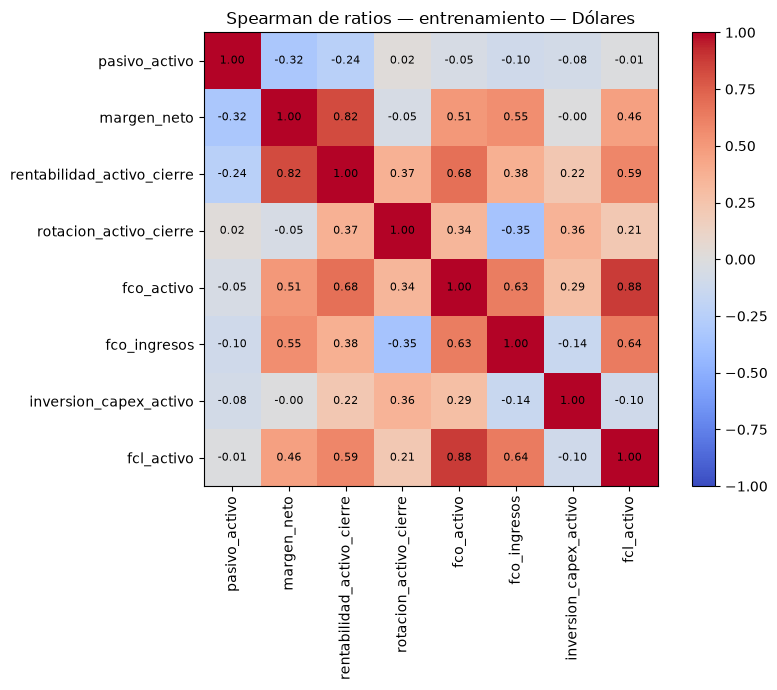

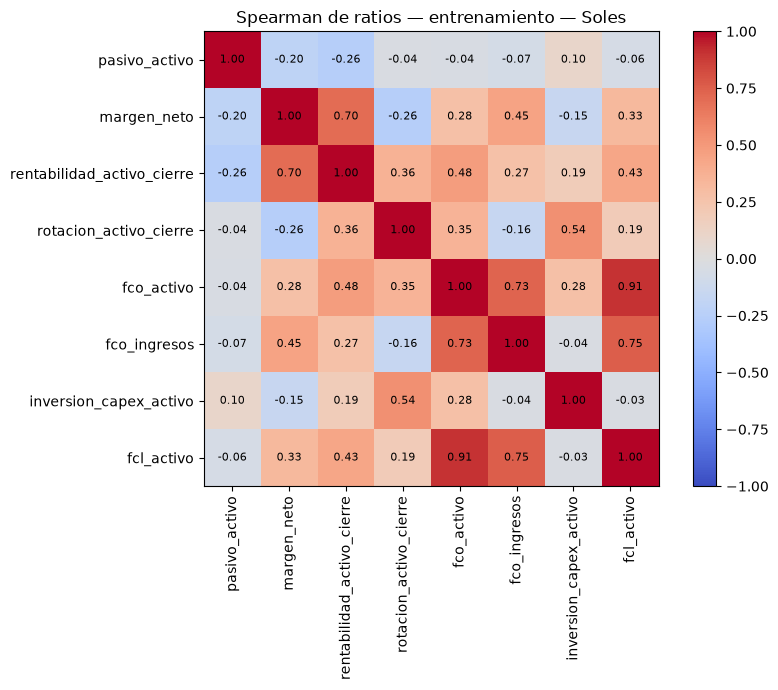

,TipoSector,Moneda,registros_train
0,A.F.P.,Soles,63
1,AGRICOLAS,Dólares,1
2,AGRICOLAS,Soles,201
3,BANCOS,Soles,172
4,DIVERSOS,Dólares,57
5,DIVERSOS,Soles,714
6,FINANCIERAS,Soles,123
7,INDUSTRIALES,Dólares,71
8,INDUSTRIALES,Soles,582
9,INDUSTRIALES DEL TRABAJO,Soles,5


In [7]:
ratio_names = PREDICTORS[:8]
for currency, tr in train.groupby("Moneda"):
    corr = tr[ratio_names].corr(method="spearman")
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(ratio_names)), ratio_names, rotation=90)
    ax.set_yticks(range(len(ratio_names)), ratio_names)
    ax.set_title(f"Spearman de ratios — entrenamiento — {DISPLAY_LABELS.get(currency, currency)}")
    for i in range(len(ratio_names)):
        for j in range(len(ratio_names)):
            value = corr.iloc[i, j]
            ax.text(j, i, f"{value:.2f}" if pd.notna(value) else "NA", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()
display(presentation(train.groupby(["TipoSector", "Moneda"]).size().rename("registros_train").reset_index()))

In [8]:
PREDICTORS_NO_COLINEALES = [c for c in PREDICTORS if c not in REDUNDANT_PREDICTORS]
assert len(PREDICTORS_NO_COLINEALES) == 19
rank_rows, vif_rows = [], []
for currency, tr in train.groupby("Moneda"):
    diagnostic = tr.loc[tr[PREDICTORS].notna().all(axis=1), PREDICTORS]
    assert len(diagnostic) > len(PREDICTORS)
    # Verificar identidades en la muestra de diagnóstico de entrenamiento.
    np.testing.assert_allclose(diagnostic.fcl_activo, diagnostic.fco_activo - diagnostic.inversion_capex_activo, atol=1e-10)
    for name in ["FCO", "FCL_preliminar"]:
        np.testing.assert_allclose(diagnostic[f"{name}_mean3_previa"], diagnostic[[f"{name}_lag{k}" for k in [1,2,3]]].mean(axis=1), atol=1e-10)
    np.testing.assert_allclose(diagnostic.rentabilidad_activo_cierre, diagnostic.margen_neto * diagnostic.rotacion_activo_cierre, atol=1e-10)
    np.testing.assert_allclose(diagnostic.fco_activo, diagnostic.fco_ingresos * diagnostic.rotacion_activo_cierre, atol=1e-10)
    for name, cols in [("original_22", PREDICTORS), ("reducido_19", PREDICTORS_NO_COLINEALES)]:
        a = diagnostic[cols].to_numpy(float)
        std = a.std(axis=0)
        z = (a - a.mean(axis=0)) / np.where(std > 0, std, 1)
        rank = np.linalg.matrix_rank(z)
        rank_rows.append(dict(moneda=currency, conjunto=name, filas=len(z), columnas=len(cols), rango=int(rank)))
        if name == "reducido_19":
            assert rank == len(cols)
        for j, col in enumerate(cols):
            y = z[:, j]
            x = np.delete(z, j, axis=1)
            residual = y - x @ np.linalg.lstsq(x, y, rcond=None)[0]
            sst, sse = y @ y, residual @ residual
            vif = np.inf if sst == 0 or sse <= 1e-12 * sst else sst / sse
            vif_rows.append(dict(moneda=currency, conjunto=name, predictor=col, VIF=vif))
rank_diagnostics, vif_diagnostics = pd.DataFrame(rank_rows), pd.DataFrame(vif_rows)
display(presentation(rank_diagnostics))
display(presentation(vif_diagnostics))
# Comparación descriptiva: no se eliminan estas filas del pipeline.
eligible_diagnostic = features.loc[features.utilizable_supervisado].copy()
eligible_diagnostic["caso_completo"] = eligible_diagnostic[PREDICTORS].notna().all(axis=1)
selection_summary = eligible_diagnostic.groupby(["Moneda", "caso_completo"]).agg(
    registros=("RPJ", "size"), empresas=("RPJ", "nunique"), activo_mediano=("ActivoTotal", "median"),
    historial_mediano=("historial_previo_contiguo", "median"), ingresos_no_positivos=("ingresos_no_positivos", "sum")).reset_index()
selection_tests = []
for currency, sub in eligible_diagnostic.groupby("Moneda"):
    a = sub.loc[sub.caso_completo, "ActivoTotal"]
    b = sub.loc[~sub.caso_completo, "ActivoTotal"]
    u, pvalue = mannwhitneyu(a, b, alternative="two-sided", method="asymptotic")
    selection_tests.append(dict(moneda=currency, completos=len(a), incompletos=len(b), U=float(u), p_exploratorio=float(pvalue)))
selection_tests = pd.DataFrame(selection_tests)
selection_by_year = eligible_diagnostic.groupby("Ejercicio").agg(elegibles=("RPJ", "size"), completos=("caso_completo", "sum")).reset_index()
revision_summary = eligible_diagnostic.groupby(["particion", "Moneda", "revision_interanual"]).agg(
    registros=("RPJ", "size"), empresas=("RPJ", "nunique")).reset_index()
revision_summary["proporcion_en_particion_moneda"] = revision_summary.registros / revision_summary.groupby(["particion", "Moneda"]).registros.transform("sum")
print("Empresas elegibles excluidas si se exigieran casos completos:",
      eligible_diagnostic.RPJ.nunique() - eligible_diagnostic.loc[eligible_diagnostic.caso_completo, "RPJ"].nunique())
display(presentation(selection_summary)); display(presentation(selection_tests)); display(selection_by_year)
display(presentation(revision_summary))
size_normalized = features[temporal].div(features.ActivoTotal.where(features.ActivoTotal.gt(0)), axis=0)
size_normalized.columns = [c + "_sobre_activo_t" for c in temporal]
size_normalized["objetivo_fcl_t1_sobre_activo_t"] = features.objetivo_fcl_t1.where(features.objetivo_moneda_consistente) / features.ActivoTotal.where(features.ActivoTotal.gt(0))
assert size_normalized.loc[~features.objetivo_moneda_consistente, "objetivo_fcl_t1_sobre_activo_t"].isna().all()
assert not np.isinf(size_normalized.to_numpy(float)).any()
print("Sensibilidad normalizada: solo en memoria; objetivo y 22 predictores exportados sin ampliación.")

,moneda,conjunto,filas,columnas,rango
0,Dólares,original_22,176,22,19
1,Dólares,reducido_19,176,19,19
2,Soles,original_22,1498,22,19
3,Soles,reducido_19,1498,19,19


,moneda,conjunto,predictor,VIF
0,Dólares,original_22,pasivo_activo,1.425534
1,Dólares,original_22,margen_neto,2.949248
2,Dólares,original_22,rentabilidad_activo_cierre,3.482953
3,Dólares,original_22,rotacion_activo_cierre,1.459900
4,Dólares,original_22,fco_activo,inf
...,...,...,...,...
77,Soles,reducido_19,cambio_FCL_preliminar_activo_previo,15.081908
78,Soles,reducido_19,FCL_preliminar_lag1,47.142815
79,Soles,reducido_19,FCL_preliminar_lag2,83.834706
80,Soles,reducido_19,FCL_preliminar_lag3,65.564129


Empresas elegibles excluidas si se exigieran casos completos: 69


,Moneda,caso_completo,registros,empresas,activo_mediano,historial_mediano,ingresos_no_positivos
0,Dólares,False,200,51,296382.5,1.0,38
1,Dólares,True,245,30,717540.0,8.0,0
2,Soles,False,1109,275,320575.0,2.0,185
3,Soles,True,2006,216,585942.5,10.0,0


,moneda,completos,incompletos,U,p_exploratorio
0,Dólares,245,200,32093.0,1.842946e-08
1,Soles,2006,1109,1370249.0,7.264818e-27


,Ejercicio,elegibles,completos
0,2005,147,0
1,2006,160,0
2,2007,164,0
3,2008,170,113
4,2009,151,115
5,2010,142,105
6,2011,168,103
7,2012,207,105
8,2013,204,107
9,2014,207,115


,particion,Moneda,revision_interanual,registros,empresas,proporcion_en_particion_moneda
0,entrenamiento,Dólares,False,229,48,0.648725
1,entrenamiento,Dólares,True,124,39,0.351275
2,entrenamiento,Soles,False,1634,257,0.649444
3,entrenamiento,Soles,True,882,240,0.350556
4,prueba,Dólares,False,74,25,0.804348
5,prueba,Dólares,True,18,13,0.195652
6,prueba,Soles,False,472,156,0.787980
7,prueba,Soles,True,127,84,0.212020


Sensibilidad normalizada: solo en memoria; objetivo y 22 predictores exportados sin ampliación.


In [9]:
display(features.groupby("particion").agg(registros=("RPJ", "size"), empresas=("RPJ", "nunique"),
    origen_min=("Ejercicio", "min"), origen_max=("Ejercicio", "max"),
    objetivo_min=("anio_objetivo", "min"), objetivo_max=("anio_objetivo", "max")))
suite = unittest.defaultTestLoader.discover(str(ROOT / "tests"), pattern="test_feature_engineering.py")
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()
assert not features.duplicated(["RPJ", "Ejercicio"]).any()
assert not np.isinf(features[PREDICTORS].to_numpy(dtype=float)).any()
assert features.loc[features.utilizable_supervisado, "objetivo_fcl_t1"].notna().all()
for k in [1, 2, 3]:
    for c in ["FCO", "FCL_preliminar"]:
        mask = features[f"{c}_lag{k}"].notna()
        assert features.loc[mask, "historial_previo_contiguo"].ge(k).all()
print("Pruebas ejecutadas:", result.testsRun, "| fallos:", len(result.failures), "| errores:", len(result.errors))

,registros,empresas,origen_min,origen_max,objetivo_min,objetivo_max
particion,,,,,,
entrenamiento,2869,302,2005,2020,2006,2021
prueba,691,187,2021,2024,2022,2025
sin_etiqueta_elegible,661,336,2005,2025,2006,2026


test_current_value_excluded_from_rolling (test_feature_engineering.FeaturesTest.test_current_value_excluded_from_rolling) ... 

ok


test_duplicates_rejected (test_feature_engineering.FeaturesTest.test_duplicates_rejected) ... 

ok


...

ok


test_target_split_missing_and_capex (test_feature_engineering.FeaturesTest.test_target_split_missing_and_capex) ... 

ok


----------------------------------------------------------------------
Ran 11 tests in 0.421s

OK


Pruebas ejecutadas: 11 | fallos: 0 | errores: 0


In [10]:
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
output = ROOT / "data/processed/features_financieras.csv"
features.to_csv(output, index=False)
def markdown_table(frame):
    def clean(v): return str(v).replace("|", "/").replace("\n", " ")
    lines = ["| " + " | ".join(map(clean, frame.columns)) + " |",
             "| " + " | ".join(["---"] * len(frame.columns)) + " |"]
    lines += ["| " + " | ".join(map(clean, row)) + " |" for row in frame.itertuples(index=False, name=None)]
    return "\n".join(lines)
(REPORTS / "diccionario_features.md").write_text(
    "# Diccionario de variables — Semana 5\n\n"
    "Predictores: 22 (8 ratios, 4 variaciones, 10 temporales). El CSV preserva columnas fuente y controles. "
    "Los valores monetarios mantienen la moneda reportada; escala no acreditada. No se convierten monedas. "
    "No hay fechas de publicación verificadas. Orden canónico: (RPJ, Ejercicio), sin índice posicional original. "
    "Ratios solo con denominadores positivos; rotación y crecimiento de ingresos exigen ingreso actual positivo. "
    "Las derivaciones de FCL invalidan CAPEX positivo; la columna fuente FCL_preliminar se conserva. "
    "Subconjunto PREDICTORS_NO_COLINEALES: 19, excluye fcl_activo y ambas medias móviles. "
    "Ventanas por empresa, segmento anual continuo y moneda constante.\n\n" + markdown_table(dictionary) + "\n", encoding="utf-8")
# Verificación de la exportación sin inferir numéricamente los identificadores.
reread = pd.read_csv(output, dtype={"RPJ": str, "RUC": str}, encoding="utf-8-sig")
assert reread.shape == features.shape
assert reread.RPJ.equals(features.RPJ)
print("Exportado:", output.relative_to(ROOT), features.shape)

Exportado: data/processed/features_financieras.csv (4221, 57)


,resultado
registros_entrada,4221
registros_exportados,4221
columnas_entrada,23
columnas_exportadas,57
empresas_observadas,336
anio_min,2005
anio_max,2025
predictores,22
fcl_actual_disponible,3898
registros_elegibles,3560


,elegibles
anio_objetivo,
2006,147
2007,160
2008,164
2009,170
2010,151
2011,142
2012,168
2013,207
2014,204


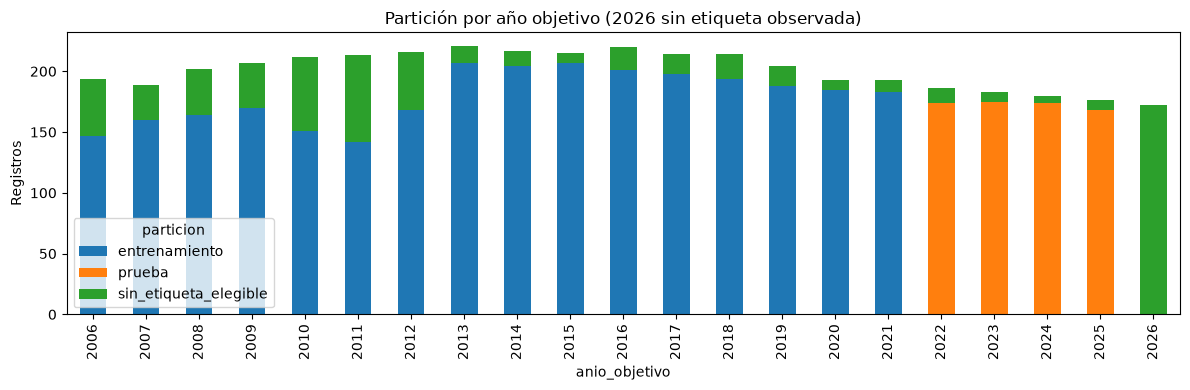

Reportes generados.


In [11]:
eligible = features.loc[features.utilizable_supervisado]
complete = eligible[PREDICTORS].notna().all(axis=1)
summary = {
    "registros_entrada": len(raw), "registros_exportados": len(features),
    "columnas_entrada": raw.shape[1], "columnas_exportadas": features.shape[1],
    "empresas_observadas": raw.RPJ.nunique(), "anio_min": int(raw.Ejercicio.min()),
    "anio_max": int(raw.Ejercicio.max()), "predictores": len(PREDICTORS),
    "fcl_actual_disponible": int(raw.FCL_preliminar.notna().sum()),
    "registros_elegibles": len(eligible), "empresas_elegibles": eligible.RPJ.nunique(),
    "casos_completos_elegibles": int(complete.sum()), "train": len(train), "test": len(test),
    "sin_etiqueta_elegible": int((~features.utilizable_supervisado).sum()),
    "pruebas_unitarias": result.testsRun,
}
display(pd.Series(summary).to_frame("resultado"))
display(eligible.groupby("anio_objetivo").size().rename("elegibles").to_frame())
counts = features.groupby(["anio_objetivo", "particion"]).size().unstack(fill_value=0)
counts.plot.bar(stacked=True, figsize=(12, 4), title="Partición por año objetivo (2026 sin etiqueta observada)")
plt.ylabel("Registros"); plt.tight_layout(); plt.show()
report = "# Semana 5 — Resultados de Feature Engineering\n\n"
report += markdown_table(pd.DataFrame(summary.items(), columns=["indicador", "valor"]))
report += "\n\n## Diseño y ejecución\n\n"
report += ("Objetivo: FCL_preliminar(t+1), aproximación FCO + CAPEX reportado con signo, no FCFF validado. "
           "22 predictores: 8 ratios, 4 variaciones, 6 rezagos y 4 estadísticas móviles. "
           "Se preservan filas, ceros y faltantes; no se imputan objetivos. "
           "Entrenamiento por año objetivo hasta 2021; prueba 2022–2025. "
           "Imputación mediana y RobustScaler en Pipeline ilustrativos por moneda ajustados solo en entrenamiento; "
           "CSV sin imputar ni escalar. No se entrenaron modelos.\n\n")
report += markdown_table(presentation(pd.DataFrame(diagnostics)))
report += "\n\nDisponibilidad de predictores en toda la exportación:\n\n"
report += markdown_table(features[PREDICTORS].notna().sum().rename_axis("predictor").reset_index(name="disponibles"))
report += ("\n\n## Validación y límites\n\n"
           f"Se ejecutaron {result.testsRun} pruebas unitarias sin fallos ni errores y aserciones sobre el panel y la exportación. "
           "La ejecución del notebook se comprueba adicionalmente mediante nbclient. "
           "La invariancia ante cambios futuros prueba el cálculo, no la disponibilidad histórica de la fuente. "
           "Faltan fechas de publicación, vintages de revisión, escala monetaria acreditada y validación de códigos FCO/CAPEX. "
           "Antes del modelado se debe purgar la frontera temporal usando fechas reales de publicación. "
           "No se mezclan monedas ni se usan tipos de cambio inventados. No hay ajuste por inflación. "
           "La moneda futura solo define elegibilidad retrospectiva. Panel desbalanceado: máximo 21 años por empresa, "
           "insuficiente para justificar por sí solo redes recurrentes y sin observaciones para estacionalidad intraanual. "
           "Sectores financieros requieren validación económica independiente. El Excel no se integró por falta de homologación.\n\n"
           "## Reproducción\n\n"
           "Entorno tesis-fcl, Python 3.12.x (ejecución verificada en 3.12.15). Dependencias en requirements-feature-engineering.txt. "
           "Ejecutar desde la raíz: `python -m unittest discover -s tests -v`; después ejecutar todas las celdas "
           "de notebooks/02_feature_engineering.ipynb con el kernel tesis-fcl, o ejecutar `python scripts/execute_feature_engineering.py`. "
           "El notebook genera únicamente los derivados autorizados; no ejecuta la ingesta ni instala paquetes.\n\n")
report += "\n\n## Correcciones Antigravity y diagnósticos\n\n"
report += ("Se conservan 22 características y se define un subconjunto de 19 sin las tres redundancias lineales exactas. "
           "Las identidades se verifican solo en entrenamiento; las dependencias DuPont son multiplicativas. "
           "Los casos completos se usan únicamente en diagnósticos; queda prohibido descartar filas mediante dropna sobre predictores en modelado. "
           "La inferencia Mann-Whitney es exploratoria: observaciones de una empresa no son independientes. "
           "RobustScaler preserva la escala intercuartílica, pero no elimina ni acota extremos. "
           "Las versiones normalizadas por ActivoTotal(t) son una sensibilidad en memoria, no nuevos predictores exportados ni un cambio del objetivo principal. "
           "La reconstrucción monetaria requiere activos y moneda de origen. La bandera revision_interanual permite estratificar, "
           "pero no demuestra por sí sola fecha o causa de una reexpresión; tampoco su ausencia garantiza datos point-in-time. "
           "La Semana 6 deberá comparar resultados por esta bandera y por moneda, auditando también las fuentes históricas de los rezagos. "
           "La imputación y el escalado deben clonarse y ajustarse dentro de cada pliegue temporal por moneda.\n\n")
report += "### Rango: solo entrenamiento completo\n\n" + markdown_table(presentation(rank_diagnostics))
report += "\n\n### VIF por predictor, solo entrenamiento\n\n" + markdown_table(presentation(vif_diagnostics))
report += "\n\n### Casos completos versus incompletos\n\n" + markdown_table(presentation(selection_summary))
report += "\n\n### Mann-Whitney por moneda (completos frente a incompletos)\n\n" + markdown_table(presentation(selection_tests))
report += "\n\n### Revisión interanual: estratificación, sin entrenar\n\n" + markdown_table(presentation(revision_summary))
report += "\n\n### Disponibilidad por año origen\n\n" + markdown_table(selection_by_year)
report += "\n\nSubconjunto recomendado de 19: `" + "`, `".join(PREDICTORS_NO_COLINEALES) + "`.\n"
report += f"SHA256 del CSV fuente: `{source_sha256}`.\n"
(REPORTS / "resumen_feature_engineering.md").write_text(report, encoding="utf-8")
print("Reportes generados.")